Our Proposition is:

 Low-income countries are more affected by climate-related disasters than high-income countries 



In [46]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
# Climate change measured in CO2 emissisons 

climate_change_data = pd.read_csv("climate-change-raw-2021.csv", skiprows = 4)
climate_change_data = climate_change_data.drop(columns="Indicator Name")
climate_change_data = climate_change_data.drop(columns="Indicator Code")
climate_change_data.head()



,Country Name,Country Code,1960,1961,1962,1963,1964,1965,1966,1967,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,Unnamed: 65
0,Aruba,ABW,50.776,50.761000,50.746000,50.730000,50.715000,50.700000,50.685000,50.670000,...,42.957000,42.990000,43.041000,43.108000,43.192000,43.293000,43.411000,43.546000,43.697000,NaN
1,Aruba,ABW,27525.000,28139.000000,28537.000000,28763.000000,28922.000000,29080.000000,29246.000000,29411.000000,...,44059.000000,44351.000000,44666.000000,44978.000000,45293.000000,45614.000000,45949.000000,46294.000000,46654.000000,NaN
2,Aruba,ABW,NaN,2.206183,1.404498,0.788835,0.551271,0.544810,0.569216,0.562594,...,0.543931,0.660561,0.707733,0.696090,0.697901,0.706219,0.731740,0.748028,0.774631,NaN
3,Aruba,ABW,54208.000,55434.000000,56234.000000,56699.000000,57029.000000,57357.000000,57702.000000,58044.000000,...,102565.000000,103165.000000,103776.000000,104339.000000,104865.000000,105361.000000,105846.000000,106310.000000,106766.000000,NaN
4,Aruba,ABW,NaN,2.236462,1.432843,0.823502,0.580334,0.573498,0.599694,0.590951,...,0.503385,0.583290,0.590508,0.541048,0.502860,0.471874,0.459266,0.437415,0.428017,NaN


In [ ]:
# GDP measured in current international dollars (PPP) per capita.

gdp = pd.read_csv(
    "GDP-Per_capita-ppp.csv",
    skiprows=4
)
gdp = gdp.drop(columns=gdp.columns[gdp.columns.str.startswith("Unnamed")])
gdp = gdp.drop(columns = "Indicator Name")
gdp = gdp.drop(columns = "Indicator Code")
gdp.head()
gdp.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 68 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Name  266 non-null    object 
 1   Country Code  266 non-null    object 
 2   1960          0 non-null      float64
 3   1961          0 non-null      float64
 4   1962          0 non-null      float64
 5   1963          0 non-null      float64
 6   1964          0 non-null      float64
 7   1965          0 non-null      float64
 8   1966          0 non-null      float64
 9   1967          0 non-null      float64
 10  1968          0 non-null      float64
 11  1969          0 non-null      float64
 12  1970          0 non-null      float64
 13  1971          0 non-null      float64
 14  1972          0 non-null      float64
 15  1973          0 non-null      float64
 16  1974          0 non-null      float64
 17  1975          0 non-null      float64
 18  1976          0 non-null      

In [ ]:
# Droughts, Floods, extreme temperatures (% of population, avg 1990-2009)
extreme_temp_data = pd.read_csv("API_EN.CLC.MDAT.ZS_DS2_en_csv_v2_9888.csv", skiprows = 4)
extreme_temp_data.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Western and Central,AFW,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Angola,AGO,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [59]:
ext = pd.read_csv("API_EN.CLC.MDAT.ZS_DS2_en_csv_v2_9888.csv", skiprows=4)

# This indicator is a single-period average, so find which year column holds the values
year_cols = [c for c in ext.columns if c.isdigit()]
has_data = ext[year_cols].notna().sum()
print(has_data[has_data > 0])          # note the column name, e.g. '2009'


val_col = "2009"   # replace with whatever column printed above

# World Bank metadata file (comes in the same download zip) has IncomeGroup
meta = pd.read_csv("Metadata_Country_API_EN.CLC.MDAT.ZS_DS2_en_csv_v2_9888.csv")

d = ext[["Country Name", "Country Code", val_col]].merge(
    meta[["Country Code", "IncomeGroup"]], on="Country Code")
d = d.rename(columns={val_col: "affected"})
d = d.dropna(subset=["affected", "IncomeGroup"])   # also removes aggregates like "World"

order = ["Low income", "Lower middle income", "Upper middle income", "High income"]
print(d.groupby("IncomeGroup")["affected"].agg(["count", "mean", "median", "max"]).reindex(order))

2009    168
dtype: int64
                     count      mean    median       max
IncomeGroup                                             
Low income              24  2.299646  1.273005  8.820493
Lower middle income     44  1.838255  0.836957  9.226586
Upper middle income     51  0.920717  0.360637  7.950971
High income             49  0.275769  0.007102  7.170624


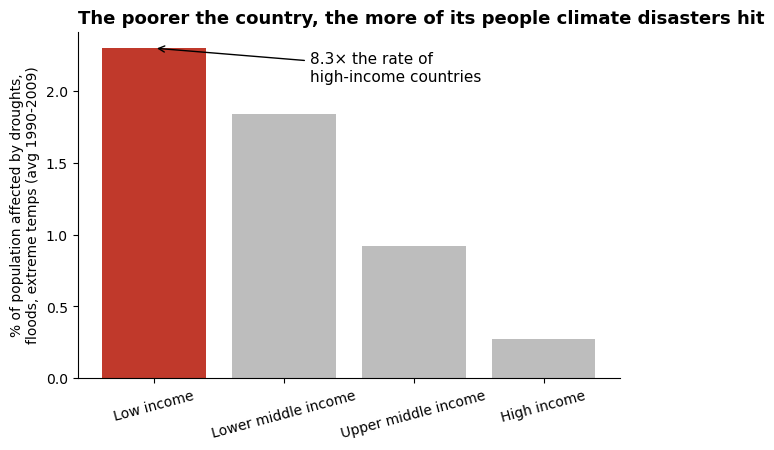

In [61]:
g = d.groupby("IncomeGroup")["affected"].mean().reindex(order)
colors = ["#c0392b", "#bdbdbd", "#bdbdbd", "#bdbdbd"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(g.index, g.values, color=colors)
ax.set_title("The poorer the country, the more of its people climate disasters hit",loc="left", fontsize=13, weight="bold")

ax.set_ylabel("% of population affected by droughts,\nfloods, extreme temps (avg 1990-2009)")

ratio = g["Low income"] / g["High income"]

ax.annotate(f"{ratio:.1f}× the rate of\nhigh-income countries", xy=(0, g["Low income"]), xytext=(1.2, g["Low income"] * 0.9), arrowprops=dict(arrowstyle="->"), fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=15)
plt.show()

Most persuasive aspects:
- the big red bar emphasizes the effect climate change has on poorer countries
The "8.3x the rate of high income countries" 

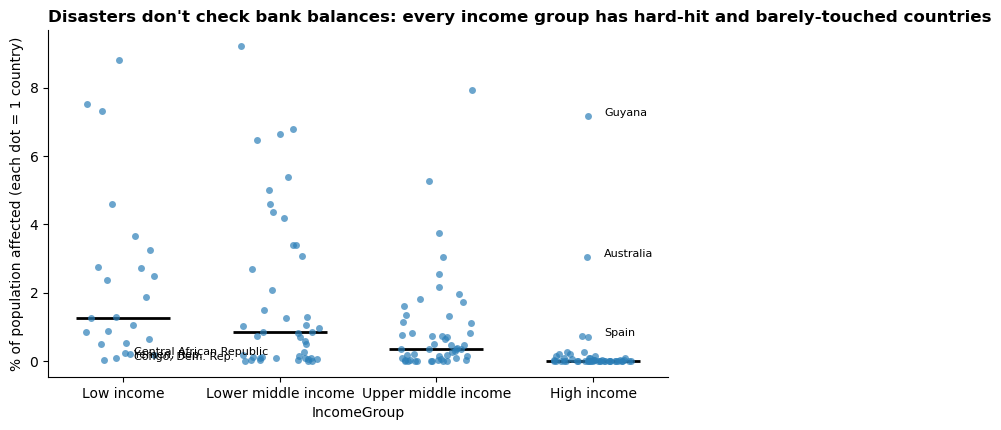

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.stripplot(data=d, x="IncomeGroup", y="affected", order=order, color="#2c7fb8", alpha=0.7, jitter=0.25, ax=ax)

med = d.groupby("IncomeGroup")["affected"].median().reindex(order)

for i, m in enumerate(med):

    ax.hlines(m, i - 0.3, i + 0.3, color="black", lw=2)

hi = d[d.IncomeGroup == "High income"].nlargest(3, "affected")

lo = d[d.IncomeGroup == "Low income"].nsmallest(3, "affected")

for _, r in pd.concat([hi, lo]).iterrows():
    ax.annotate(r["Country Name"], (order.index(r["IncomeGroup"]), r["affected"]), xytext=(8, 0), textcoords="offset points", fontsize=8)

ax.set_title("Disasters don't check bank balances: every income group has hard-hit and barely-touched countries", loc="left", fontsize=12, weight="bold")

ax.set_ylabel("% of population affected (each dot = 1 country)")

ax.spines[["top", "right"]].set_visible(False)

plt.show()